# 01. Exploratory Data Analysis (EDA)
## E-Commerce Customer Churn & Lifetime Value (LTV) Predictor
This notebook provides key data cleaning verification, transaction dynamics, country distribution, RFM profiles, and the target churn rate overview.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
DATA_PATH = '../data/processed/clean_transactions.csv'
df = pd.read_csv(DATA_PATH)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print('Loaded clean transactions shape:', df.shape)
df.head()

Loaded clean transactions shape: (805549, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


### 1. Dataset Shape & Missing Values Before / After Cleaning

In [2]:
summary_table = pd.DataFrame({
    'Stage': ['Raw UCI Online Retail II', 'Cleaned Transactions'],
    'Rows': [1067371, len(df)],
    'Missing CustomerIDs': [243007, 0],
    'Cancelled Invoices': [19494, 0],
    'Non-positive Qty/Price': [22950, 0]
})
summary_table

,Stage,Rows,Missing CustomerIDs,Cancelled Invoices,Non-positive Qty/Price
0,Raw UCI Online Retail II,1067371,243007,19494,22950
1,Cleaned Transactions,805549,0,0,0


### 2. Monthly Revenue Trend & Monthly Active Customers
Examining seasonal sales patterns and active customer trends over the 2-year lifespan.

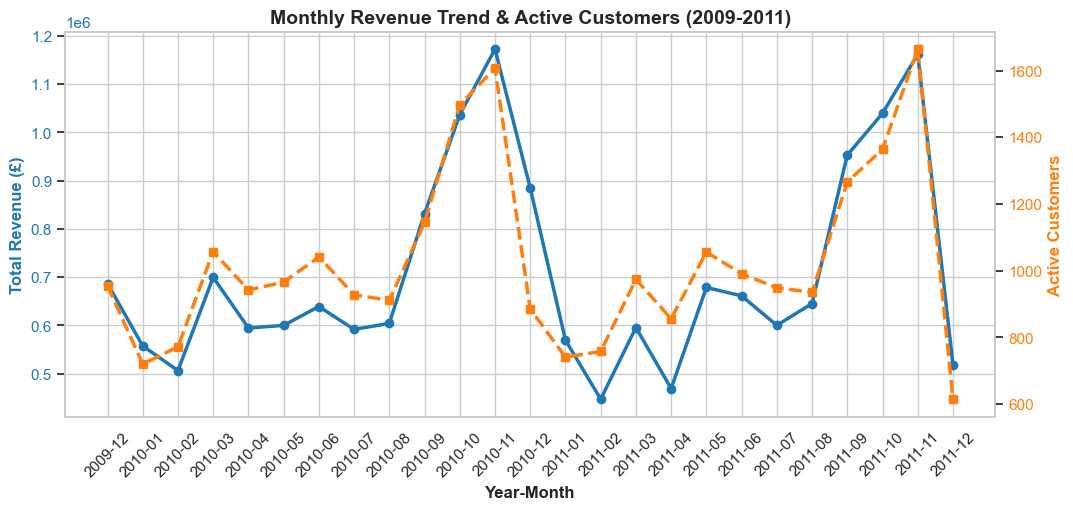

In [3]:
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M').astype(str)
monthly = df.groupby('YearMonth').agg(Revenue=('Revenue', 'sum'), ActiveCustomers=('CustomerID', 'nunique')).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
color = '#1f77b4'
ax1.plot(monthly['YearMonth'], monthly['Revenue'], color=color, marker='o', linewidth=2.5, label='Monthly Revenue')
ax1.set_xlabel('Year-Month', fontweight='bold')
ax1.set_ylabel('Total Revenue (£)', color=color, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color)
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
color = '#ff7f0e'
ax2.plot(monthly['YearMonth'], monthly['ActiveCustomers'], color=color, marker='s', linestyle='--', linewidth=2.5, label='Active Customers')
ax2.set_ylabel('Active Customers', color=color, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color)
ax2.grid(False)
plt.title('Monthly Revenue Trend & Active Customers (2009-2011)', fontsize=14, fontweight='bold')
plt.show()

### 3. Orders per Customer Distribution (Log Scale)
Checking repeat purchasing behavior across the customer base.

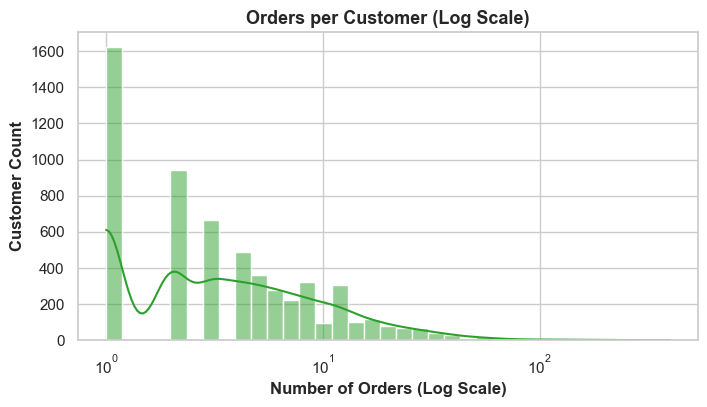

In [4]:
orders_per_cust = df.groupby('CustomerID')['Invoice'].nunique()
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(orders_per_cust, log_scale=True, bins=35, kde=True, color='#2ca02c', ax=ax)
ax.set_title('Orders per Customer (Log Scale)', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Orders (Log Scale)', fontweight='bold')
ax.set_ylabel('Customer Count', fontweight='bold')
plt.show()

### 4. Top 10 Countries by Revenue
Evaluating geographic market concentration.

C:\Users\nites\AppData\Local\Temp\ipykernel_32472\3112556486.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_countries, x='Revenue', y='Country', palette='Blues_r', ax=ax)


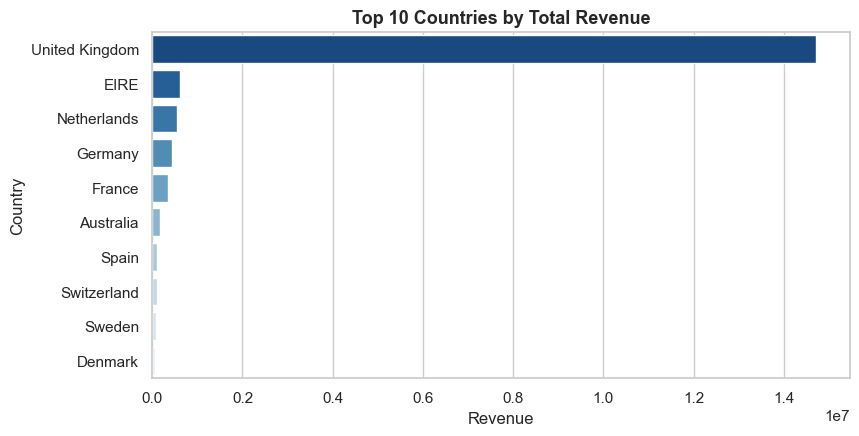

In [5]:
top_countries = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10).reset_index()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=top_countries, x='Revenue', y='Country', palette='Blues_r', ax=ax)
ax.set_title('Top 10 Countries by Total Revenue', fontsize=13, fontweight='bold')
plt.show()

### 5. RFM Distributions and Correlation Heatmap

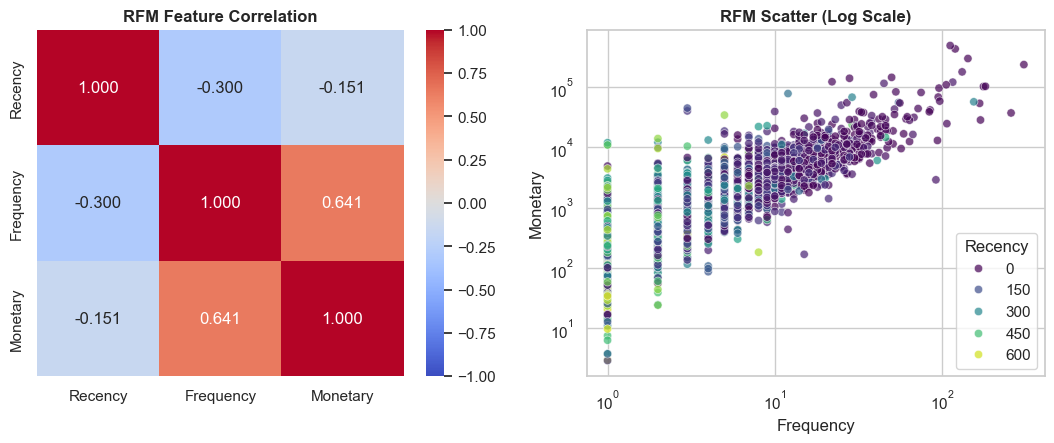

In [6]:
max_date = df['InvoiceDate'].max()
cutoff_date = max_date - pd.Timedelta(days=90)
obs_df = df[df['InvoiceDate'] < cutoff_date]
rfm = obs_df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda d: (cutoff_date - d.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(rfm[['Recency', 'Frequency', 'Monetary']].corr(), annot=True, cmap='coolwarm', fmt='.3f', ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title('RFM Feature Correlation', fontweight='bold')
sns.scatterplot(data=rfm, x='Frequency', y='Monetary', hue='Recency', palette='viridis', alpha=0.7, ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_xscale('log')
axes[1].set_title('RFM Scatter (Log Scale)', fontweight='bold')
plt.show()

### 6. Churn Rate Overview (Phase 2 Target Definition)
Cutoff = Last InvoiceDate minus 90 days. Churn = 1 if no purchases made in the 90 days after cutoff.

Total Observed Customers: 5281
Churned: 2989 (56.60%)
Retained: 2292 (43.40%)


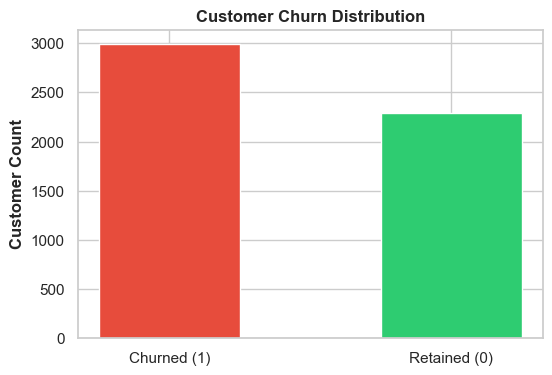

In [7]:
perf_df = df[df['InvoiceDate'] >= cutoff_date]
obs_custs = set(obs_df['CustomerID'].unique())
perf_custs = set(perf_df['CustomerID'].unique())

churn_labels = pd.Series([1 if cid not in perf_custs else 0 for cid in obs_custs])
counts = churn_labels.value_counts()
print(f'Total Observed Customers: {len(obs_custs)}')
print(f'Churned: {counts[1]} ({counts[1]/len(obs_custs):.2%})')
print(f'Retained: {counts[0]} ({counts[0]/len(obs_custs):.2%})')

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Churned (1)', 'Retained (0)'], [counts[1], counts[0]], color=['#e74c3c', '#2ecc71'], width=0.5)
ax.set_title('Customer Churn Distribution', fontweight='bold')
ax.set_ylabel('Customer Count', fontweight='bold')
plt.show()